# data visualization (random)

In [ ]:
import pandas as pd
data=pd.read_csv('diabetes.csv')
# data.head()
# data.info()
# data.dtypes
data.describe()
# data= data.replace(0,pd.NA)

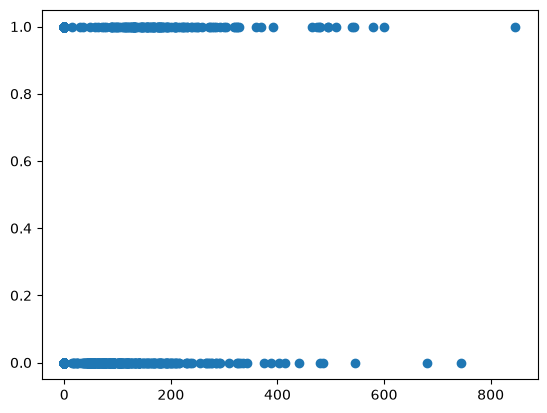

In [20]:
x = data[['Insulin']]
y = data[['Outcome']]

import matplotlib.pyplot as plt

plt.scatter(x, y)

plt.show()

### Glucose and BMI both has less than 5% missing value so we can use univarient imputer like mean ,median 
distort the distribution and covarienece with other input feature


In [27]:
data['Glucose'] = data['Glucose'].replace(0, pd.NA)
# calculate mean
median_value = data['Glucose'].median()

print( median_value)
data['Glucose'] = data['Glucose'].fillna(median_value)
data[data['Glucose'].isnull()]
data['Glucose'] = pd.to_numeric(data['Glucose'])
#Glucose column is done 

117.0


In [ ]:
#strat bmi
data['BMI']= data['BMI'].replace(0,pd.NA)
data['BMI']= data['BMI'].fillna(data['BMI'].median)
data[data['BMI'].isnull()]
data['BMI'] = pd.to_numeric(data['BMI'])
#bmi done

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


##### srtart the BloodPressure with median imputation 

In [28]:

data['BloodPressure'].describe()
data['BloodPressure']=data['BloodPressure'].replace(0,pd.NA)
data['BloodPressure']=data['BloodPressure'].fillna(data['BloodPressure'].median())
data['BloodPressure']=pd.to_numeric(data['BloodPressure'])

#####
we got error because BMI and "float() argument must be a string or a real number, not 'method'
Output is truncated"  DiabetesPedigreeFunction doest not have int type 


In [ ]:
data['BMI'] = pd.to_numeric(data['BMI'], errors='coerce')
# i do not know bout coerce i take reference from gemini when i get errorInvalid object type During handling of the above exception, another exception occurred:
data['DiabetesPedigreeFunction']=pd.to_numeric(data['DiabetesPedigreeFunction'])

In [ ]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

KnnData= data.drop('Outcome',axis=1)
# what is axis i do not know when i get error i take refernce feom chatgpt
# KnnData.info()
scaler = StandardScaler()
KnnData_scaled = scaler.fit_transform(KnnData)
imputer=KNNImputer()
predict=imputer.fit_transform(KnnData_scaled)
# print(predict)
predict=scaler.inverse_transform(predict)
# print(predict)
data[KnnData.columns]=predict


[[  6.    148.     72.    ...  33.6     0.627  50.   ]
 [  1.     85.     66.    ...  26.6     0.351  31.   ]
 [  8.    183.     64.    ...  23.3     0.672  32.   ]
 ...
 [  5.    121.     72.    ...  26.2     0.245  30.   ]
 [  1.    126.     60.    ...  30.1     0.349  47.   ]
 [  1.     93.     70.    ...  30.4     0.315  23.   ]]
Insulin          0
SkinThickness    0
dtype: int64
